In [1]:
import pandas as pd

# Load dataset
model_df = pd.read_csv("../data/processed/03_model_training_dataset.csv")

# Display first 5 rows
display(model_df.head())

# Display all column names
print("\nColumns in the dataset:")
print(model_df.columns.tolist())

# Display dataset dimensions
print("\nDataset shape:", model_df.shape)

,year,lat,lon,month_sin,month_cos,rainfall_anomaly_lag_1,rainfall_anomaly_lag_2,rainfall_anomaly_lag_3,rainfall_anomaly_rolling_3m,rainfall_anomaly_rolling_6m,rainfall_anomaly_std_3m,temperature_anomaly_lag_1,temperature_anomaly_lag_2,temperature_anomaly_lag_3,temperature_anomaly_rolling_3m,rainfall_anomaly
0,1951,8.5,77.5,-0.500000,-8.660254e-01,43.484516,22.288481,89.001956,51.591651,23.505317,34.087625,-0.902,0.056,-0.982,-0.609333,-22.638708
1,1951,8.5,77.5,-0.866025,-5.000000e-01,-22.638708,43.484516,22.288481,14.378096,16.766826,33.763898,-0.421,-0.902,0.056,-0.422333,-34.401511
2,1951,8.5,77.5,-1.000000,-1.836970e-16,-34.401511,-22.638708,43.484516,-4.518568,14.470587,41.985866,0.321,-0.421,-0.902,-0.334000,76.465412
3,1951,8.5,77.5,-0.866025,5.000000e-01,76.465412,-34.401511,-22.638708,6.475064,29.033358,60.898091,0.191,0.321,-0.421,0.030333,-70.360432
4,1951,8.5,77.5,-0.500000,8.660254e-01,-70.360432,76.465412,-34.401511,-9.432177,2.472960,76.531418,0.609,0.191,0.321,0.373667,117.969890



Columns in the dataset:
['year', 'lat', 'lon', 'month_sin', 'month_cos', 'rainfall_anomaly_lag_1', 'rainfall_anomaly_lag_2', 'rainfall_anomaly_lag_3', 'rainfall_anomaly_rolling_3m', 'rainfall_anomaly_rolling_6m', 'rainfall_anomaly_std_3m', 'temperature_anomaly_lag_1', 'temperature_anomaly_lag_2', 'temperature_anomaly_lag_3', 'temperature_anomaly_rolling_3m', 'rainfall_anomaly']

Dataset shape: (252031, 16)


In [2]:
# Display column data types and non-null counts
model_df.info()

# Check missing values in each column
print("\nMissing values:")
display(model_df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252031 entries, 0 to 252030
Data columns (total 16 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   year                            252031 non-null  int64  
 1   lat                             252031 non-null  float64
 2   lon                             252031 non-null  float64
 3   month_sin                       252031 non-null  float64
 4   month_cos                       252031 non-null  float64
 5   rainfall_anomaly_lag_1          252031 non-null  float64
 6   rainfall_anomaly_lag_2          252031 non-null  float64
 7   rainfall_anomaly_lag_3          252031 non-null  float64
 8   rainfall_anomaly_rolling_3m     252031 non-null  float64
 9   rainfall_anomaly_rolling_6m     252031 non-null  float64
 10  rainfall_anomaly_std_3m         252031 non-null  float64
 11  temperature_anomaly_lag_1       252031 non-null  float64
 12  temperature_anom

year                              0
lat                               0
lon                               0
month_sin                         0
month_cos                         0
rainfall_anomaly_lag_1            0
rainfall_anomaly_lag_2            0
rainfall_anomaly_lag_3            0
rainfall_anomaly_rolling_3m       0
rainfall_anomaly_rolling_6m       0
rainfall_anomaly_std_3m           0
temperature_anomaly_lag_1         0
temperature_anomaly_lag_2         0
temperature_anomaly_lag_3         0
temperature_anomaly_rolling_3m    0
rainfall_anomaly                  0
dtype: int64

Rainfall Anomaly – Descriptive Statistics


count    252031.000000
mean          0.605011
std          72.281108
min        -874.500861
25%         -19.481876
50%          -4.040488
75%          12.061923
max        1784.010598
Name: rainfall_anomaly, dtype: float64

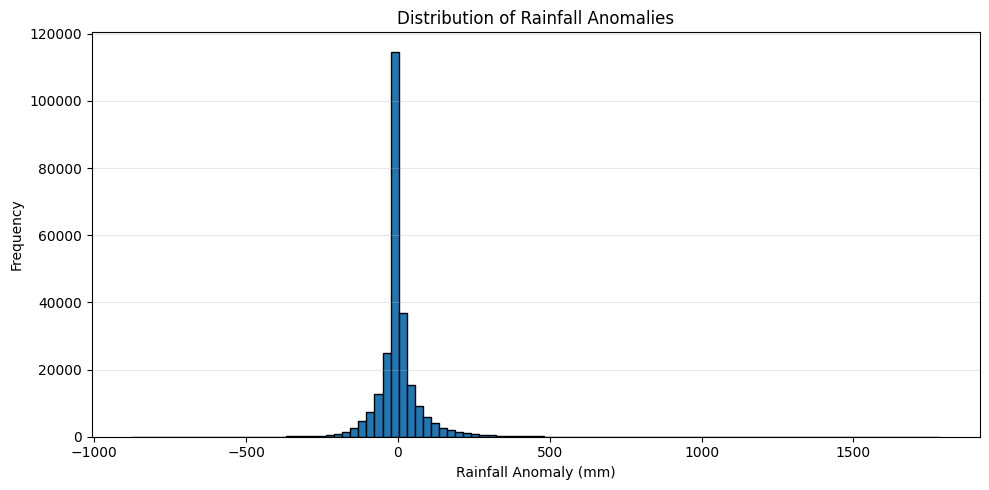

In [ ]:
#understanding dataset distribution
import matplotlib.pyplot as plt

# Statistical summary of the target
print("Rainfall Anomaly – Descriptive Statistics")
display(model_df["rainfall_anomaly"].describe())

# Distribution of rainfall anomalies
plt.figure(figsize=(10, 5))
plt.hist(model_df["rainfall_anomaly"], bins=100, edgecolor="black")

plt.title("Distribution of Rainfall Anomalies")
plt.xlabel("Rainfall Anomaly (mm)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Examine extreme percentiles
percentiles = [0.001, 0.01, 0.05, 0.95, 0.99, 0.999]

print("Rainfall Anomaly – Extreme Percentiles")
display(model_df["rainfall_anomaly"].quantile(percentiles))

# Calculate skewness and kurtosis
print("\nSkewness:", model_df["rainfall_anomaly"].skew())
print("Kurtosis:", model_df["rainfall_anomaly"].kurtosis())

# Count observations outside the 1st and 99th percentiles
lower = model_df["rainfall_anomaly"].quantile(0.01)
upper = model_df["rainfall_anomaly"].quantile(0.99)

print("\nObservations below 1st percentile:", (model_df["rainfall_anomaly"] < lower).sum())
print("Observations above 99th percentile:", (model_df["rainfall_anomaly"] > upper).sum())

Rainfall Anomaly – Extreme Percentiles


0.001   -351.615542
0.010   -180.302162
0.050    -96.646134
0.950    116.990820
0.990    257.033422
0.999    525.158468
Name: rainfall_anomaly, dtype: float64


Skewness: 1.8019272885823394
Kurtosis: 20.569153029676954

Observations below 1st percentile: 2521
Observations above 99th percentile: 2521


In [6]:
# Identify the 10 lowest and 10 highest rainfall anomalies

print("10 Lowest Rainfall Anomalies:")
display(
    model_df.nsmallest(10, "rainfall_anomaly")[
        ["year", "lat", "lon", "rainfall_anomaly"]
    ]
)

print("\n10 Highest Rainfall Anomalies:")
display(
    model_df.nlargest(10, "rainfall_anomaly")[
        ["year", "lat", "lon", "rainfall_anomaly"]
    ]
)

10 Lowest Rainfall Anomalies:


,year,lat,lon,rainfall_anomaly
31080,2008,16.5,73.5,-874.500861
167766,2000,25.5,91.5,-852.003300
167838,2006,25.5,91.5,-812.022191
167310,1962,25.5,91.5,-802.985160
39126,2008,17.5,73.5,-795.033061
167262,1958,25.5,91.5,-785.971582
167298,1961,25.5,91.5,-763.464888
167346,1965,25.5,91.5,-748.642357
167910,2012,25.5,91.5,-734.552877
167898,2011,25.5,91.5,-718.317882



10 Highest Rainfall Anomalies:


,year,lat,lon,rainfall_anomaly
167454,1974,25.5,91.5,1784.010598
167135,2022,25.5,90.5,1700.706757
168029,2022,25.5,91.5,1312.300343
167051,2015,25.5,90.5,1309.241694
167456,1974,25.5,91.5,1251.052998
167574,1984,25.5,91.5,1160.990108
219817,1958,28.5,95.5,1154.649132
166572,1975,25.5,90.5,1148.388714
48030,2005,18.5,73.5,1088.985397
166991,2010,25.5,90.5,1081.382338


In [7]:
import numpy as np

# Recover month from cyclic encoding
model_df["month"] = (
    np.round(
        np.mod(
            np.arctan2(
                model_df["month_sin"],
                model_df["month_cos"]
            ),
            2 * np.pi
        ) * 12 / (2 * np.pi)
    ).astype(int) % 12
) + 1

# Display extreme observations with their months
extreme_df = pd.concat([
    model_df.nsmallest(10, "rainfall_anomaly"),
    model_df.nlargest(10, "rainfall_anomaly")
])

display(
    extreme_df[
        ["year", "month", "lat", "lon", "rainfall_anomaly"]
    ].sort_values("rainfall_anomaly")
)

,year,month,lat,lon,rainfall_anomaly
31080,2008,8,16.5,73.5,-874.500861
167766,2000,8,25.5,91.5,-852.003300
167838,2006,8,25.5,91.5,-812.022191
167310,1962,8,25.5,91.5,-802.985160
39126,2008,8,17.5,73.5,-795.033061
167262,1958,8,25.5,91.5,-785.971582
167298,1961,8,25.5,91.5,-763.464888
167346,1965,8,25.5,91.5,-748.642357
167910,2012,8,25.5,91.5,-734.552877
167898,2011,8,25.5,91.5,-718.317882
